In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def BankChurn_data_reader(filename='Churn.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['Exited'],axis = 1)
    y = data['Exited']
    return X, y

In [2]:
rsts = {}

rsts['SHAP'] = {
    'SHAP': {
        'values': [
           ('Age', 0.832777),
            ('NumOfProducts', 0.782540),
            ('IsActiveMember', 0.540072),
            ('Gender', 0.305541),
            ('Balance', 0.229651),
            ('Geography', 0.190220),
            ('HasCrCard', 0.083545),
            ('CreditScore', 0.069511),
            ('Tenure', 0.057795),
            ('EstimatedSalary', 0.048417)
        ],
        'duration': 1.0917768478393555
    }
}

rsts['LIME'] = {
    'LIME': {
        'values': [
            ('NumOfProducts', 0.1655358222427533),
            ('Age', 0.1493821490735118),
            ('IsActiveMember', 0.1462127684497249),
            ('Gender', 0.0690296939279221),
            ('Geography', 0.02714965770282531),
            ('Balance', 0.02698494594688002),
            ('EstimatedSalary', 0.013254122309414923),
            ('Tenure', 0.005133974035111853),
            ('CreditScore', 0.0003512193199641317),
            ('HasCrCard', 0.0)
        ],
        'duration': 0.25426816940307617
    }
}
rsts['Feature Importance'] = {
    'Feature Importance': {
        'values': [
            ('Balance', 559),
            ('CreditScore', 515),
            ('EstimatedSalary', 474),
            ('Age', 386),
            ('Geography', 270),
            ('Tenure', 210),
            ('IsActiveMember', 183),
            ('Gender', 170),
            ('NumOfProducts', 158),
            ('HasCrCard', 75)
        ],
        'duration': 0.044457197189331055
    }
}

rsts['Permutation Feature Importance'] = {
    'Permutation Feature Importance': {
        'values': [
            ('Age', 1.000000),
            ('NumOfProducts', 0.562328),
            ('IsActiveMember', 0.349972),
            ('Balance', 0.192499),
            ('Geography', 0.180640),
            ('Gender', 0.090734),
            ('CreditScore', 0.010480),
            ('HasCrCard', 0.003861),
            ('EstimatedSalary', 0.001103),
            ('Tenure', 0.000000)
        ],
        'duration': 0.38964295387268066
    }
}

rsts['ShapG'] = {
    'ShapG': {
        'values': [
           ('Age', 0.851064164739701),
            ('NumOfProducts', 0.1659668249965402),
            ('IsActiveMember', 0.11033918696755055),
            ('Gender', 0.08209270088552269),
            ('Geography', 0.06034823415653269),
            ('Balance', 0.06006074725201206),
            ('CreditScore', 0.026001442430150894),
            ('HasCrCard', 0.009480500171233294),
            ('EstimatedSalary', 0.0),
            ('Tenure', 0.0)
        ],
        'duration': 212.91736316680908
    }
}

rsts['FastSHAP'] = {
    'FastSHAP': {
        'values': [
          ('Age', 24378.684),
('NumOfProducts', 21717.29),
('Geography', 10186.917),
('Gender', 10140.717),
('IsActiveMember', 16176.898),
('Balance', 5437.9004),
('HasCrCard', 2730.3682),
('CreditScore', 2236.1646),
('EstimatedSalary', 1655.3857),
('Tenure', 1400.04)
        ],
        'duration': 1060.90
    }
}

In [3]:
import pandas as pd

# 提取每个方法的特征排序
methods = {
    'SHAP': [feature for feature, _ in rsts['SHAP']['SHAP']['values']],
     # 'SamplingSHAP': [feature for feature, _ in rsts['SamplingSHAP']['SamplingSHAP']['values']],
    # 'KernelSHAP': [feature for feature, _ in rsts['KernelSHAP']['KernelSHAP']['values']],
    'LIME': [feature for feature, _ in rsts['LIME']['LIME']['values']],
    'Feature Importance': [feature for feature, _ in rsts['Feature Importance']['Feature Importance']['values']],
    'Permutation Feature Importance': [feature for feature, _ in rsts['Permutation Feature Importance']['Permutation Feature Importance']['values']],
    'ShapG': [feature for feature, _ in rsts['ShapG']['ShapG']['values']],
    'FastSHAP': [feature for feature, _ in rsts['FastSHAP']['FastSHAP']['values']]
}

# 创建 DataFrame
df = pd.DataFrame(methods)

# 显示 DataFrame
df

,SHAP,LIME,Feature Importance,Permutation Feature Importance,ShapG,FastSHAP
0,Age,NumOfProducts,Balance,Age,Age,Age
1,NumOfProducts,Age,CreditScore,NumOfProducts,NumOfProducts,NumOfProducts
2,IsActiveMember,IsActiveMember,EstimatedSalary,IsActiveMember,IsActiveMember,Geography
3,Gender,Gender,Age,Balance,Gender,Gender
4,Balance,Geography,Geography,Geography,Geography,IsActiveMember
5,Geography,Balance,Tenure,Gender,Balance,Balance
6,HasCrCard,EstimatedSalary,IsActiveMember,CreditScore,CreditScore,HasCrCard
7,CreditScore,Tenure,Gender,HasCrCard,HasCrCard,CreditScore
8,Tenure,CreditScore,NumOfProducts,EstimatedSalary,EstimatedSalary,EstimatedSalary
9,EstimatedSalary,HasCrCard,HasCrCard,Tenure,Tenure,Tenure


In [4]:
# global mapping of colors and markers
colors = {
    'SHAP': 'c',  
    'SamplingSHAP': 'm',
    'SamplingSHAP (KernelSHAP)': 'm',
    'KernelSHAP': 'purple',
    'LIME': 'g',
    'Feature Importance':'y',
    'Permutation Feature Importance':'b',
    'ShapG': 'r',
    'FastSHAP':'orange'
}
markers = {
    'SHAP': 'o',  
    'SamplingSHAP': '+',
    'SamplingSHAP (KernelSHAP)': '+',
    'KernelSHAP': 's',  # 添加了 KernelSHAP 的标记符号
    'LIME': '^',  # 添加了 LIME 的标记符号
    'Feature Importance': '<',  # 添加了 Feature Importance 的标记符号
    'Permutation Feature Importance': 'v',  # 添加了 Permutation Feature Importance 的标记符号
    'ShapG': '*',
    'FastSHAP': 'X'
}

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, accuracy_score
import lightgbm as lgb

def compute_weighted_slope(metrics, beta=0.8):
    """
    Compute the weighted slope of accuracy changes.

    Parameters:
    - metrics: List of metric values (e.g., accuracy or R^2).
    - beta: Weight decay factor (default: 0.8).

    Returns:
    - slope: Weighted slope value.
    """
    deltas = [metrics[i] - metrics[i + 1] for i in range(len(metrics) - 1)]
    weights = [beta**i for i in range(len(deltas))]
    slope = np.dot(deltas, weights)
    return slope

def plot_feature_dropping_effects(X, y, method2dict, limit=10, plot_title='Comparison of accuracy after dropping features (LightGBM)', filename=None):
    """
    Function to plot the effect on prediction accuracy of dropping features based on various ratios of method2dict.

    Parameters:
    X (DataFrame): Feature matrix.
    y (Series/DataFrame): Target variable.
    method2dict (dict): Dictionary containing feature ranks and other details.
    limit (int): Maximum number of features to drop.
    plot_title (str): Title for the plot.
    filename (str): File name to save the plot (optional).

    Returns:
    results (dict): Dictionary containing the features dropped and corresponding accuracies for each method.
    """
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    model = lgb.LGBMClassifier(verbose=-1, random_state=42)  # fixed seed for reproducibility


    # Fit initial model
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    initial_accuracy = accuracy_score(y_test, pred)

    results = {}
    plt.figure(figsize=(10, 6))  # 调整图形大小以适应图例

    # Plot for each method
    for method, rst_dict in method2dict.items():
        for k, v in rst_dict.items():
            metrics = [initial_accuracy]
            deltas = []
            feature_rank = [x[0] for x in v['values']]

            # Drop features and calculate accuracy
            for i in range(1, limit):
                features_to_drop = feature_rank[:i]
                reduced_X = X.drop(columns=features_to_drop)

                X_train, X_test, y_train, y_test = train_test_split(reduced_X, y, test_size=0.3, random_state=42)
                model.fit(X_train, y_train)
                pred = model.predict(X_test)
                new_accuracy = accuracy_score(y_test, pred)

                deltas.append(metrics[-1] - new_accuracy)
                metrics.append(new_accuracy)

            # Compute weighted slope
            slope = compute_weighted_slope(metrics)

            # Store results
            results[k] = {
                'Features': feature_rank,
                'Metrics': metrics,
                'S': slope
            }

            # Plot with method-specific color and marker
            label = f'{k} (S: {slope:.4f})'
            plt.plot(
                range(0, limit), 
                metrics, 
                marker=markers.get(method, 'o'), 
                color=colors.get(method, 'k'),
                label=label, 
                linewidth=1.5, 
                alpha=0.7
            )

    # Customize plot
    plt.xlabel('Number of Features Dropped')
    plt.ylabel('Accuracy')
    # plt.title(plot_title)
    plt.xticks(range(0, limit))
    plt.grid()

    # Place legend inside the plot
    plt.legend(loc='upper right', fontsize='small', frameon=True)

    # Save plot if filename is provided
    if filename:
        plt.savefig(filename, format='eps', dpi=300, bbox_inches='tight')

    plt.show()

    return results


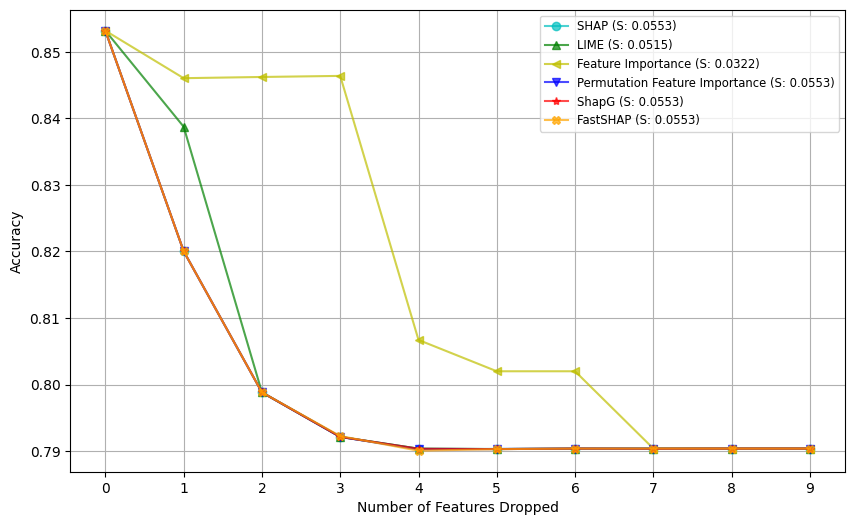


各方法的 Slope 和 Duration:
SHAP: Slope=0.0553, Duration=1.0918s
LIME: Slope=0.0515, Duration=0.2543s
Feature Importance: Slope=0.0322, Duration=0.0445s
Permutation Feature Importance: Slope=0.0553, Duration=0.3896s
ShapG: Slope=0.0553, Duration=212.9174s
FastSHAP: Slope=0.0553, Duration=1060.9000s


In [6]:
X, y = BankChurn_data_reader('Churn.csv')

results = plot_feature_dropping_effects(X, y, rsts, limit=10, filename='Compare-bank-lgb-n.eps') 

combined_results = {}
for method_name, result_dict in results.items():
    # 从原始 rsts 中获取 duration
    duration = None
    for key, val in rsts.items():
        if method_name in val:
            duration = val[method_name]['duration']
            break
    
    combined_results[method_name] = {
        'Slope': result_dict['S'],
        'duration': duration,
        'Metrics': result_dict['Metrics'],
        'Features': result_dict['Features']
    }

print("\n各方法的 Slope 和 Duration:")
for method, data in combined_results.items():
    print(f"{method}: Slope={data['Slope']:.4f}, Duration={data['duration']:.4f}s")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


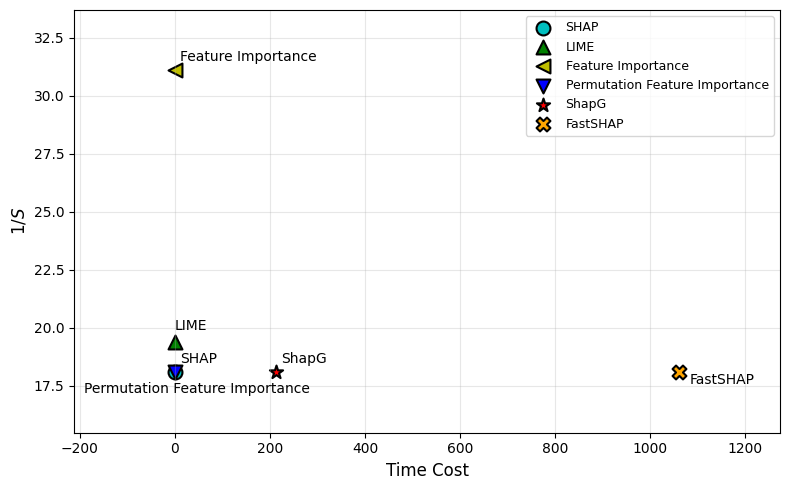

In [7]:
def plot_by_triple(triple, title='Comparison of Time Cost and $1/S$', filename=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # 准备数据
    x = [t[1] for t in triple]
    y = [1/t[0] for t in triple]
    labels = [t[2] for t in triple]
    
    # 计算数据范围
    x_range = max(x) - min(x)
    y_range = max(y) - min(y)
    
    # 设置适当的边距
    margin = 0.2
    ax.set_xlim(min(x) - margin * x_range, max(x) + margin * x_range)
    ax.set_ylim(min(y) - margin * y_range, max(y) + margin * y_range)
    
    # 绘制散点，使用全局定义的 colors 和 markers
    for i, txt in enumerate(labels):
        ax.scatter(
            x[i],
            y[i],
            color=colors.get(txt, 'k'),
            marker=markers.get(txt, 'o'),
            edgecolors='black',
            s=100,
            linewidths=1.5,
            label=txt
        )
    
    # 为每个方法手动设置标签偏移位置，避免重叠
    label_offsets = {
        'SHAP': (0.01, 0.02),
        'LIME': (0.00, 0.03),
        'Permutation Feature Importance': (-0.18, -0.08),
        'ShapG': (0.01, 0.02),
       'Feature Importance': (0.01, 0.02),
        'FastSHAP': (0.02, -0.05)
    }
    
    # 添加文本标签
    for i, txt in enumerate(labels):
        offset_x_ratio, offset_y_ratio = label_offsets.get(txt, (0.03, 0.03))
        offset_x = x_range * offset_x_ratio
        offset_y = y_range * offset_y_ratio
        
        ax.text(
            x[i] + offset_x,
            y[i] + offset_y,
            txt,
            fontsize=10,
            color='black',
            horizontalalignment='left',
            verticalalignment='bottom'
        )
    
    ax.set_xlabel('Time Cost', fontsize=12)
    ax.set_ylabel('$1/S$', fontsize=12)
    # ax.set_title(title, fontsize=14)
    ax.legend(fontsize=9, loc='best')
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    
    if filename:
        plt.savefig(filename, format='eps', dpi=300, bbox_inches='tight')
    
    plt.show()

def plot_by_rsts(rsts, title='Comparison of Time Cost and $1/S$', filename=None):
    """
    rsts: dict of results
    """
    triple = []
    for method, data in rsts.items():
        slope = data['Slope']
        time = data['duration']
        triple.append((slope, time, method))
    plot_by_triple(triple, title, filename)


plot_by_rsts(combined_results, filename='Time-Vs-S-Churn-lgb.eps')

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


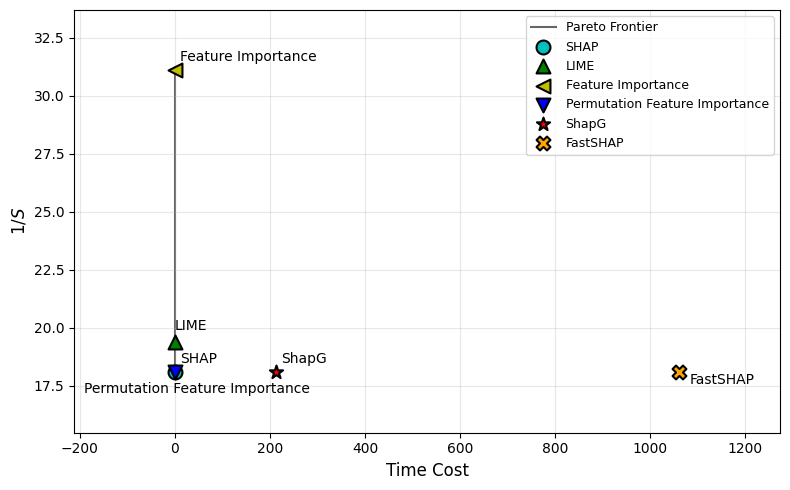

In [8]:
def compute_pareto_frontier(points):
    """
    Compute Pareto frontier for minimization of both x (Time Cost) and y (1/S).
    points: list of (x, y, label) tuples
    Returns list of Pareto optimal points sorted by x.

    Uses a relative tolerance on y (1/S) to avoid spurious non-domination caused
    by floating-point noise when two methods have essentially the same slope S.
    If two points have |y1 - y2| < eps (1% of y_range), the faster one dominates.
    """
    y_vals = [p[1] for p in points]
    y_range = max(y_vals) - min(y_vals)
    eps = 0.01 * y_range if y_range > 0 else 1e-10

    pareto = []
    for i, (x1, y1, lbl1) in enumerate(points):
        dominated = False
        for j, (x2, y2, _) in enumerate(points):
            if i == j:
                continue
            # Point j dominates point i if:
            #   j is not slower, AND j's quality is not worse (within tolerance),
            #   AND j is strictly better in at least one dimension.
            x_weakly_better = x2 <= x1
            y_weakly_better = y2 <= y1 + eps          # within tolerance counts as "not worse"
            x_strictly_better = x2 < x1
            y_strictly_better = y2 < y1 - eps         # must be meaningfully better to count
            if x_weakly_better and y_weakly_better and (x_strictly_better or y_strictly_better):
                dominated = True
                break
        if not dominated:
            pareto.append((x1, y1, lbl1))
    pareto.sort(key=lambda p: p[0])
    return pareto


def plot_by_rsts_pareto(rsts, title='Comparison of Time Cost and $1/S$', filename=None):
    """
    Same as plot_by_rsts but with Pareto frontier connecting the non-dominated points.
    """
    triple = []
    for method, data in rsts.items():
        slope = data['Slope']
        time = data['duration']
        triple.append((slope, time, method))

    fig, ax = plt.subplots(figsize=(8, 5))

    x = [t[1] for t in triple]
    y = [1 / t[0] for t in triple]
    labels = [t[2] for t in triple]

    x_range = max(x) - min(x)
    y_range = max(y) - min(y)

    margin = 0.2
    ax.set_xlim(min(x) - margin * x_range, max(x) + margin * x_range)
    ax.set_ylim(min(y) - margin * y_range, max(y) + margin * y_range)

    # --- Pareto frontier ---
    points = list(zip(x, y, labels))
    pareto = compute_pareto_frontier(points)
    px = [p[0] for p in pareto]
    py = [p[1] for p in pareto]
    # Draw staircase: horizontal then vertical steps (step-post), NOT diagonal lines
    ax.step(px, py, 'k-', where='post', linewidth=1.5, alpha=0.6, zorder=1, label='Pareto Frontier')

    # --- Scatter all points ---
    for i, txt in enumerate(labels):
        ax.scatter(
            x[i], y[i],
            color=colors.get(txt, 'k'),
            marker=markers.get(txt, 'o'),
            edgecolors='black',
            s=100,
            linewidths=1.5,
            label=txt,
            zorder=2
        )
    label_offsets = {
        'SHAP': (0.01, 0.02),
        'LIME': (0.00, 0.03),
        'Permutation Feature Importance': (-0.18, -0.08),
        'ShapG': (0.01, 0.02),
        'Feature Importance': (0.01, 0.02),
        'FastSHAP': (0.02, -0.05)
    }
    
    # 添加文本标签
    for i, txt in enumerate(labels):
        offset_x_ratio, offset_y_ratio = label_offsets.get(txt, (0.03, 0.03))
        offset_x = x_range * offset_x_ratio
        offset_y = y_range * offset_y_ratio
        
        ax.text(
            x[i] + offset_x,
            y[i] + offset_y,
            txt,
            fontsize=10,
            color='black',
            horizontalalignment='left',
            verticalalignment='bottom'
        )

    ax.set_xlabel('Time Cost', fontsize=12)
    ax.set_ylabel('$1/S$', fontsize=12)
    ax.legend(fontsize=9, loc='best')
    ax.grid(alpha=0.3)

    plt.tight_layout()

    if filename:
        plt.savefig(filename, format='eps', dpi=300, bbox_inches='tight')

    plt.show()

plot_by_rsts_pareto(combined_results, filename='Time-Vs-S-Churn-lgb-Pareto.eps')
# plot_by_rsts_pareto(combined_results)
